[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/diogoflim/iap/blob/main/05_Gradientes_Inicializacao.ipynb)

# UNIVERSIDADE FEDERAL FLUMINENSE

**TCE11616 - Introdução ao Aprendizado Profundo**

**Prof.: Diogo Ferreira de Lima Silva**

---
# AULA 05 — GRADIENTES E OS "BOTÕES" DO TREINAMENTO
---

Nas últimas aulas, usamos sempre as mesmas linhas mágicas: `perda.backward()` e `otimizador.step()`.

Vamos entender, de forma intuitiva, o que elas fazem e aprender a regular os principais "botões" do treinamento.

Veremos:
- o que é o **gradiente** e como o PyTorch o calcula;
- como o otimizador usa o gradiente para **descer** a perda;
- o efeito da **taxa de aprendizado** (`lr`);
- os otimizadores **SGD** e **Adam**;
- o efeito do **tamanho do lote** e do **número de épocas**.
- por que o **ponto de partida** dos pesos (a **inicialização**) pode decidir se uma rede profunda aprende ou não.

## 0. Importando as bibliotecas

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)      # fixa a semente: os resultados ficam iguais a cada execução

# cores usadas nos gráficos
LARANJA, AZUL, VERDE, VERMELHO, CINZA = "#E08D2B", "#1F7A8C", "#2E7D4F", "#B3151A", "#5B6472"

---
## 1. O que é o gradiente?
---

Imagine que você está em um morro, no meio da neblina, e quer chegar ao ponto mais baixo. Você não vê o vale, mas sente a **inclinação** do chão sob seus pés. Uma estratégia simples: dar um passo para o lado em que o chão **desce**.

O treinamento da rede segue um processo semelhante: os parâmetros são a sua posição, a perda é a altura do terreno, e o otimizador dá passos morro abaixo.

### Um exemplo com um único parâmetro

Vamos minimizar uma "perda" bem simples:

$$ \text{perda}(w) = (w - 3)^2 $$

O menor valor (zero) acontece em $w = 3$. Vamos ver se o PyTorch encontra isso sozinho.

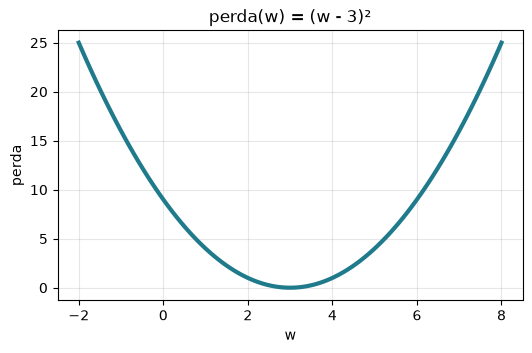

In [ ]:
w_valores = torch.linspace(-2, 8, 100)

plt.figure(figsize=(6, 3.5))
plt.plot(w_valores, (w_valores - 3) ** 2, color=AZUL, linewidth=3)
plt.xlabel("w"); plt.ylabel("perda"); plt.title("perda(w) = (w - 3)²"); plt.grid(alpha=0.3)
plt.show()

O argumento `requires_grad=True` pede ao PyTorch para **acompanhar** as contas feitas com `w`. Depois de calcular a perda, `perda.backward()` calcula a inclinação e a guarda em `w.grad`.

In [ ]:
w = torch.tensor(0.0, requires_grad=True)     # ponto de partida: w = 0

perda = (w - 3) ** 2
perda.backward()                               # calcula o gradiente

print("w        =", w.item())
print("perda    =", perda.item())
print("gradiente=", w.grad.item())

w        = 0.0
perda    = 9.0
gradiente= -6.0


w.grad retornou **−6**. De fato, a derivada de $(w-3)^2$ é $2(w-3)$, que vale $-6$ em $w = 0$.

**Assim, a perda **diminui** se aumentarmos $w$.**

### Gradiente descendente

A regra da **descida de gradiente** é: andar um pouquinho **contra** o gradiente.

$$ w \leftarrow w - \text{lr} \times \text{gradiente} $$

O `lr` (*learning rate*, **taxa de aprendizado**) é o tamanho do passo.

In [ ]:
w = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for passo in range(10):
    perda = (w - 3) ** 2
    perda.backward()

    with torch.no_grad():
        w -= lr * w.grad        # dá um passo contra o gradiente

    w.grad.zero_()              # zera o gradiente para o próximo passo

    print(f"passo {passo + 1:2d}: w = {w.item():.4f} | perda = {perda.item():.4f}")

passo  1: w = 0.6000 | perda = 9.0000
passo  2: w = 1.0800 | perda = 5.7600
passo  3: w = 1.4640 | perda = 3.6864
passo  4: w = 1.7712 | perda = 2.3593
passo  5: w = 2.0170 | perda = 1.5099
passo  6: w = 2.2136 | perda = 0.9664
passo  7: w = 2.3709 | perda = 0.6185
passo  8: w = 2.4967 | perda = 0.3958
passo  9: w = 2.5973 | perda = 0.2533
passo 10: w = 2.6779 | perda = 0.1621


O $w$ caminha em direção a 3 e a perda cai a cada passo.

**É exatamente isso que o otimizador faz.** As três linhas do nosso laço de treino correspondem a esse código:

| Laço de treino | O que faz |
|---|---|
| `otimizador.zero_grad()` | `w.grad.zero_()` para todos os parâmetros |
| `perda.backward()` | calcula o gradiente de todos os parâmetros |
| `otimizador.step()` | `w -= lr * w.grad` para todos os parâmetros |

Uma rede neural tem milhares de parâmetros em vez de um, mas a ideia é a mesma.

### O tamanho do passo importa

Vamos repetir a descida com três taxas de aprendizado diferentes. Desta vez usamos o otimizador `torch.optim.SGD`, que faz a mesma conta para nós.

In [ ]:
# função auxiliar

def descer(lr, passos=15):
    w = torch.tensor(0.0, requires_grad=True)
    otimizador = torch.optim.SGD([w], lr=lr)
    caminho = [w.item()]
    for passo in range(passos):
        perda = (w - 3) ** 2
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        caminho.append(w.item())
    return caminho

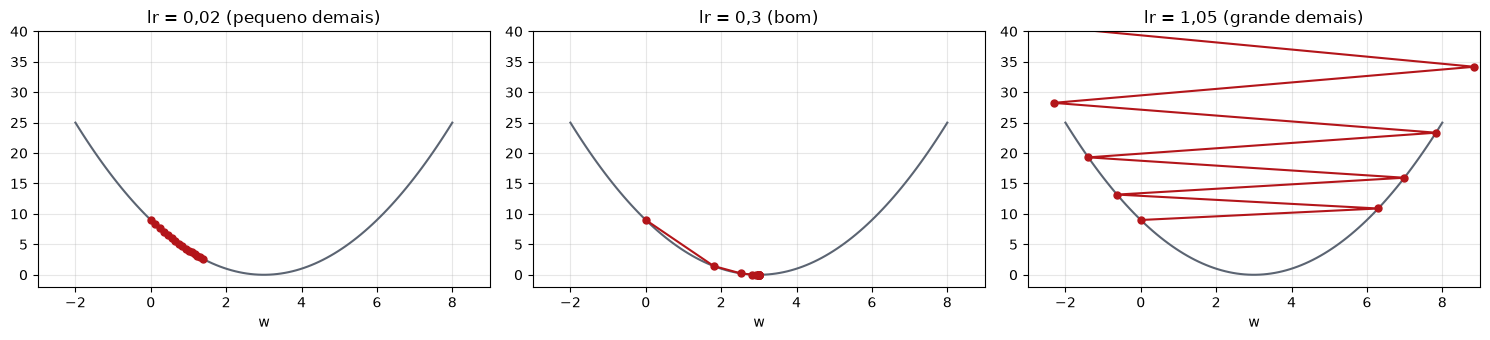

In [ ]:
plt.figure(figsize=(15, 3.5))

for i, (lr, titulo) in enumerate([(0.02, "lr = 0,02 (pequeno demais)"),
                                  (0.3,  "lr = 0,3 (bom)"),
                                  (1.05, "lr = 1,05 (grande demais)")]):
    caminho = np.array(descer(lr))
    plt.subplot(1, 3, i + 1)
    plt.plot(w_valores, (w_valores - 3) ** 2, color=CINZA)
    plt.plot(caminho, (caminho - 3) ** 2, "o-", color=VERMELHO, markersize=5)
    plt.title(titulo); plt.xlabel("w"); plt.ylim(-2, 40); plt.xlim(-3, 9); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- **lr pequeno demais**: os passos são minúsculos; depois de 15 passos ainda estamos longe do fundo.
- **lr bom**: chegamos perto de $w = 3$ rapidamente.
- **lr grande demais**: cada passo "pula" por cima do vale e cai mais alto do outro lado. A perda **aumenta** e o treino **diverge**.

Escolher a taxa de aprendizado é o ajuste mais importante do treinamento.

---
## 2. Um conjunto de dados para experimentar
---

Usaremos o conjunto **digits** do scikit-learn: 1 797 imagens pequenas ($8 \times 8$ pixels) de dígitos de 0 a 9.

É um "MNIST em miniatura".

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digitos = load_digits()
print("formato dos dados:", digitos.data.shape)    # 1797 imagens, cada uma com 64 pixels

formato dos dados: (1797, 64)


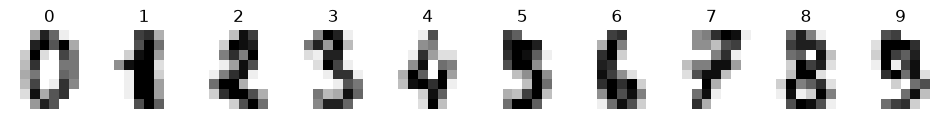

In [ ]:
plt.figure(figsize=(12, 2.2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(digitos.images[i], cmap="gray_r")
    plt.title(digitos.target[i]); plt.axis("off")
plt.show()

Iniciaremos separando o conjunto de dados nos conjuntos de treino e teste. Então, realizaremos a conversão para tensores.

Os pixels vão de 0 a 16; dividimos por 16 para que fiquem entre 0 e 1.

Os rótulos de classificação com várias classes são **inteiros**, por isso usamos `dtype=torch.long`.

In [ ]:
X_tr, X_te, y_tr, y_te = train_test_split(digitos.data, digitos.target, test_size=0.3, random_state=42)

X_treino = torch.tensor(X_tr / 16, dtype=torch.float32)
X_teste  = torch.tensor(X_te / 16, dtype=torch.float32)
Y_treino = torch.tensor(y_tr, dtype=torch.long)
Y_teste  = torch.tensor(y_te, dtype=torch.long)

print("X_treino:", X_treino.shape, "| Y_treino:", Y_treino.shape)

X_treino: torch.Size([1257, 64]) | Y_treino: torch.Size([1257])


Duas funções auxiliares: uma cria a rede (sempre a mesma, para comparar só o treino) e outra mede a acurácia.

In [ ]:
def criar_rede():
    return nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))


def acuracia(modelo, X, Y):
    with torch.no_grad():
        previsto = modelo(X).argmax(dim=1)
    return (previsto == Y).float().mean().item()

E a função de treino, que agora recebe o **otimizador** como argumento. Assim podemos testar otimizadores e taxas de aprendizado diferentes sem mudar o laço.

In [ ]:
def treinar(modelo, otimizador, epocas=200):
    perda_fn = nn.CrossEntropyLoss()
    historico = []
    for epoca in range(epocas):
        perda = perda_fn(modelo(X_treino), Y_treino)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        historico.append(perda.item())
    return historico

---
## 3. Botão 1: a taxa de aprendizado
---

Treinamos a mesma rede com SGD e quatro taxas de aprendizado.

lr = 0.001  | perda final = 2.295 | acurácia no teste = 12.4%
lr = 0.01   | perda final = 2.188 | acurácia no teste = 45.0%
lr = 0.1    | perda final = 0.488 | acurácia no teste = 90.9%
lr = 1.0    | perda final = 0.055 | acurácia no teste = 97.6%


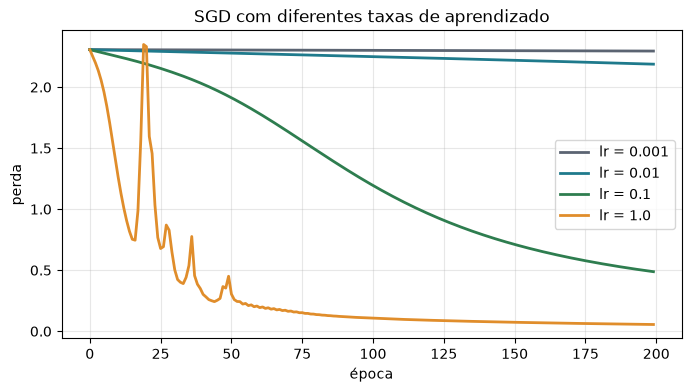

In [ ]:
plt.figure(figsize=(8, 4))
for lr, cor in zip([0.001, 0.01, 0.1, 1.0], [CINZA, AZUL, VERDE, LARANJA]):
    torch.manual_seed(42)
    rede = criar_rede()
    historico = treinar(rede, torch.optim.SGD(rede.parameters(), lr=lr))
    print(f"lr = {lr:<6} | perda final = {historico[-1]:.3f} | acurácia no teste = {acuracia(rede, X_teste, Y_teste):.1%}")
    plt.plot(historico, color=cor, linewidth=2, label=f"lr = {lr}")

plt.xlabel("época"); plt.ylabel("perda"); plt.title("SGD com diferentes taxas de aprendizado")
plt.legend(); plt.grid(alpha=0.3); plt.show()

O mesmo comportamento do exemplo de uma variável: com `lr` pequeno a perda quase não sai do lugar em 200 épocas; aumentando o `lr`, o treino fica bem mais rápido.

---
## 4. Botão 2: o otimizador (SGD × Adam)
---

O **Adam** é uma versão "esperta" da descida de gradiente: ele ajusta o tamanho do passo de cada parâmetro automaticamente. Na prática, ele costuma funcionar bem em uma faixa maior de taxas de aprendizado.

In [ ]:
print(f"{'lr':>7} | {'SGD':>6} | {'Adam':>6}")
print("-" * 26)
for lr in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    resultados = []
    for Otimizador in [torch.optim.SGD, torch.optim.Adam]:
        torch.manual_seed(42)
        rede = criar_rede()
        treinar(rede, Otimizador(rede.parameters(), lr=lr))
        resultados.append(acuracia(rede, X_teste, Y_teste))
    print(f"{lr:>7} | {resultados[0]:>6.1%} | {resultados[1]:>6.1%}")

     lr |    SGD |   Adam
--------------------------
 0.0001 |  12.2% |  56.9%
  0.001 |  12.4% |  93.7%
   0.01 |  45.0% |  97.6%
    0.1 |  90.9% |  97.0%
    1.0 |  97.6% |  14.4%


Repare que:

- o SGD só funciona bem com taxas de aprendizado **altas** neste problema;
- o Adam funciona bem com taxas **entre 0,001 e 0,1**, mas também **falha** se o `lr` for grande demais (1,0).

Não existe taxa de aprendizado universal: cada problema e cada otimizador têm a sua faixa boa.

> **Regra prática:** comece com `torch.optim.Adam(modelo.parameters(), lr=0.001)`. Se a perda cair devagar demais, aumente o `lr` 10 vezes; se a perda ficar instável ou aumentar, diminua.

---
## 5. Botão 3: o tamanho do lote
---

Até agora, em cada passo a rede via **todos** os dados de treino. Na Aula 04 (MNIST), usamos **lotes** de 64 imagens com o `DataLoader`. Qual a diferença?

- **Lote completo:** 1 passo por época, com o gradiente "exato".
- **Lotes pequenos:** muitos passos por época, cada um com um gradiente aproximado (calculado com poucos exemplos).

Vamos comparar, com o mesmo número de épocas, usando o Adam.

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

dados_treino = TensorDataset(X_treino, Y_treino)     # junta X e Y em um único conjunto


def treinar_em_lotes(modelo, tamanho_lote, epocas=30):
    carregador = DataLoader(dados_treino, batch_size=tamanho_lote, shuffle=True)
    perda_fn = nn.CrossEntropyLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
    acuracias = []
    for epoca in range(epocas):
        for xb, yb in carregador:
            perda = perda_fn(modelo(xb), yb)
            otimizador.zero_grad()
            perda.backward()
            otimizador.step()
        acuracias.append(acuracia(modelo, X_teste, Y_teste))     # mede ao fim de cada época
    return acuracias

lote = 8 (158 passos por época)          acurácia final = 96.7%
lote = 32 (40 passos por época)          acurácia final = 95.9%
lote = 128 (10 passos por época)         acurácia final = 93.7%
lote = 1257 (1 passos por época)         acurácia final = 68.3%


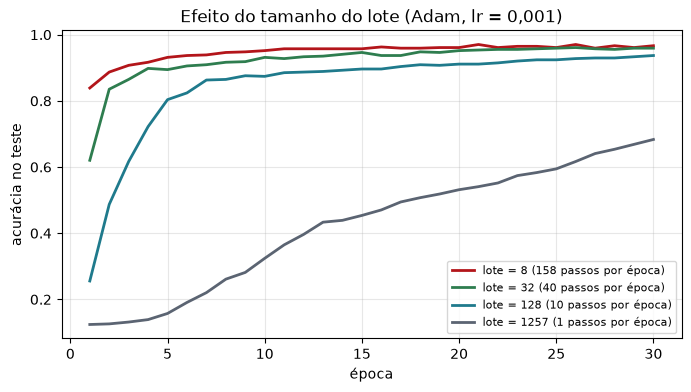

In [ ]:
plt.figure(figsize=(8, 4))
for tamanho, cor in zip([8, 32, 128, len(X_treino)], [VERMELHO, VERDE, AZUL, CINZA]):
    torch.manual_seed(42)
    rede = criar_rede()
    acuracias = treinar_em_lotes(rede, tamanho)
    n_passos = len(DataLoader(dados_treino, batch_size=tamanho))
    rotulo = f"lote = {tamanho} ({n_passos} passos por época)"
    plt.plot(range(1, 31), acuracias, color=cor, linewidth=2, label=rotulo)
    print(f"{rotulo:<40} acurácia final = {acuracias[-1]:.1%}")

plt.xlabel("época"); plt.ylabel("acurácia no teste"); plt.title("Efeito do tamanho do lote (Adam, lr = 0,001)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

Com lotes pequenos, a rede dá **muito mais passos** por época e aprende em menos épocas. Com o lote completo, ela dá só um passo por época e, em 30 épocas, fica bem atrás (cerca de 70% de acurácia).

Por outro lado, lotes muito pequenos deixam cada passo mais "barulhento" e não aproveitam bem o processamento em paralelo do computador (especialmente da GPU). Na prática, valores entre **32 e 256** são os mais usados.

---
## 6. Botão 4: o número de épocas
---

Quantas épocas treinar? Vamos acompanhar a acurácia de **treino** e de **teste** ao longo de muitas épocas.

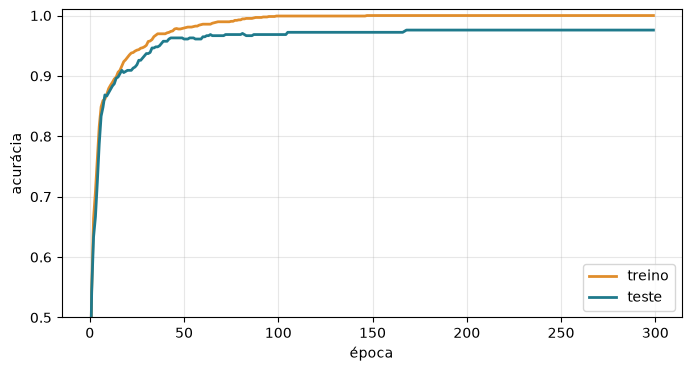

acurácia final -> treino: 100.0% | teste: 97.6%


In [ ]:
torch.manual_seed(42)
rede = criar_rede()
otimizador = torch.optim.Adam(rede.parameters(), lr=0.01)
perda_fn = nn.CrossEntropyLoss()

acc_treino, acc_teste = [], []
for epoca in range(300):
    perda = perda_fn(rede(X_treino), Y_treino)
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()
    acc_treino.append(acuracia(rede, X_treino, Y_treino))
    acc_teste.append(acuracia(rede, X_teste, Y_teste))

plt.figure(figsize=(8, 4))
plt.plot(acc_treino, color=LARANJA, linewidth=2, label="treino")
plt.plot(acc_teste, color=AZUL, linewidth=2, label="teste")
plt.xlabel("época"); plt.ylabel("acurácia"); plt.ylim(0.5, 1.01)
plt.legend(); plt.grid(alpha=0.3); plt.show()

print(f"acurácia final -> treino: {acc_treino[-1]:.1%} | teste: {acc_teste[-1]:.1%}")

- No começo, as duas curvas sobem juntas: a rede está aprendendo padrões úteis.
- Depois, a acurácia de treino chega a **100%**, enquanto a de teste para de melhorar. A partir daí, treinar mais não ajuda.

A diferença entre treino e teste é um sinal importante, que estudaremos com cuidado nas próximas aulas.

---
## 7. Botão 5: a inicialização
---

Antes do treino começar, a rede precisa de valores para **todos** os seus pesos. O PyTorch os sorteia ao criar cada camada: é a **inicialização**. Na imagem do morro da Seção 1, a inicialização é o **ponto de partida** da descida.

Veja: a mesma camada criada com duas sementes diferentes começa com pesos diferentes.

In [ ]:
torch.manual_seed(0)
camada_a = nn.Linear(64, 64)
torch.manual_seed(1)
camada_b = nn.Linear(64, 64)

print("alguns pesos com semente 0:", camada_a.weight[0, :5].detach())
print("alguns pesos com semente 1:", camada_b.weight[0, :5].detach())

alguns pesos com semente 0: tensor([-0.0009,  0.0671, -0.1029, -0.0920, -0.0481])
alguns pesos com semente 1: tensor([ 0.0644, -0.0552, -0.0242,  0.0587, -0.1177])


### A sorte conta um pouco

Partindo de pontos diferentes, a descida termina em lugares um pouco diferentes. Treinando a rede da Seção 2 com 5 sementes:

In [ ]:
for semente in range(5):
    torch.manual_seed(semente)
    rede = criar_rede()
    treinar(rede, torch.optim.Adam(rede.parameters(), lr=0.01))
    print(f"semente {semente}: acurácia no teste = {acuracia(rede, X_teste, Y_teste):.1%}")

semente 0: acurácia no teste = 97.6%
semente 1: acurácia no teste = 98.0%
semente 2: acurácia no teste = 97.2%
semente 3: acurácia no teste = 97.6%
semente 4: acurácia no teste = 97.2%


As diferenças são pequenas aqui, mas lembre disso ao comparar modelos: uma diferença de poucos décimos pode ser só sorte.

### O tamanho dos pesos iniciais importa muito

Mais importante que a sorte é a **escala** dos números sorteados. Em uma rede com uma camada oculta, como a de cima, quase qualquer escolha razoável funciona. Em uma rede **profunda**, não.

Vamos montar uma rede com **10 camadas ocultas** e inicializá-la de quatro formas, usando as funções do módulo `nn.init`:

| Modo | O que faz |
|---|---|
| `"padrão"` | deixa os pesos sorteados pelo próprio PyTorch |
| `"pequena"` | pesos sorteados com desvio **0,01** (pequenos demais) |
| `"grande"` | pesos sorteados com desvio **1,0** (grandes demais) |
| `"He"` | `nn.init.kaiming_normal_`: desvio escolhido de acordo com o tamanho da camada, pensado para redes com ReLU |

In [ ]:
def criar_rede_profunda(n_camadas=10):
    camadas = [nn.Linear(64, 64), nn.ReLU()]
    for i in range(n_camadas - 1):
        camadas += [nn.Linear(64, 64), nn.ReLU()]
    camadas.append(nn.Linear(64, 10))
    return nn.Sequential(*camadas)


def inicializar(rede, modo):
    for camada in rede:
        if isinstance(camada, nn.Linear):            # só as camadas Linear têm pesos
            if modo == "pequena":
                nn.init.normal_(camada.weight, mean=0.0, std=0.01)
            elif modo == "grande":
                nn.init.normal_(camada.weight, mean=0.0, std=1.0)
            elif modo == "He":
                nn.init.kaiming_normal_(camada.weight)
            if modo != "padrão":
                nn.init.zeros_(camada.bias)          # vieses começam em zero
    return rede


modos = ["padrão", "pequena", "grande", "He"]
cores_modo = {"padrão": CINZA, "pequena": AZUL, "grande": VERMELHO, "He": VERDE}

### O sinal ao longo da rede

Antes de treinar, vamos passar os dados de treino pela rede e medir, depois de cada camada, o **tamanho** dos números que saem (o desvio-padrão). É o mesmo laço `for camada in rede` que usamos na Aula 08 para ver os formatos.

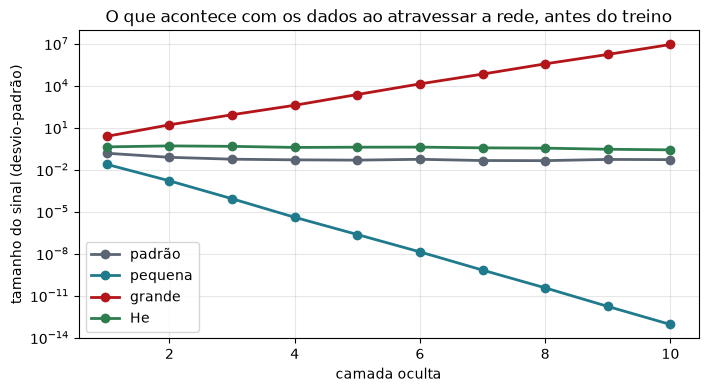

In [ ]:
plt.figure(figsize=(8, 4))
for modo in modos:
    torch.manual_seed(42)
    rede = inicializar(criar_rede_profunda(), modo)

    tamanhos = []
    h = X_treino
    with torch.no_grad():
        for camada in rede:
            h = camada(h)
            if isinstance(camada, nn.ReLU):
                tamanhos.append(h.std().item())

    plt.plot(range(1, 11), tamanhos, "o-", color=cores_modo[modo], linewidth=2, label=modo)

plt.yscale("log")
plt.xlabel("camada oculta"); plt.ylabel("tamanho do sinal (desvio-padrão)")
plt.title("O que acontece com os dados ao atravessar a rede, antes do treino")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

Repare na escala logarítmica do eixo vertical (cada marca é 10 vezes a anterior):

- **pesos pequenos**: a cada camada o sinal encolhe; depois de 10 camadas ele praticamente **some**;
- **pesos grandes**: a cada camada o sinal cresce; depois de 10 camadas ele **explode** para milhões;
- **padrão do PyTorch**: o sinal não some, mas fica cerca de 100 vezes menor que com He já nas primeiras camadas;
- **He**: o sinal se mantém do mesmo tamanho do começo ao fim.

E o gradiente, que percorre a rede **de trás para frente**, sofre o mesmo problema: some ou explode. Sem gradiente útil, a rede não sabe como corrigir os pesos.

### O efeito no treino

Treinamos as quatro versões com o SGD (`lr = 0,1`) e a função `treinar` da Seção 2:

padrão   | perda final = 2.302 | acurácia no teste = 9.3%


pequena  | perda final = 2.302 | acurácia no teste = 9.3%


grande   | perda final = nan | acurácia no teste = 9.8%


He       | perda final = 0.076 | acurácia no teste = 95.6%


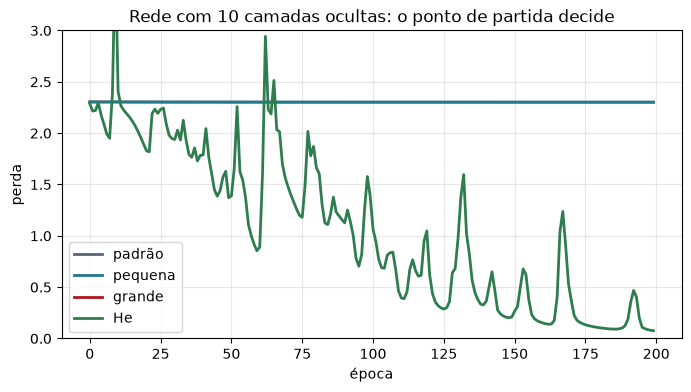

In [ ]:
plt.figure(figsize=(8, 4))
for modo in modos:
    torch.manual_seed(42)
    rede = inicializar(criar_rede_profunda(), modo)
    historico = treinar(rede, torch.optim.SGD(rede.parameters(), lr=0.1))
    plt.plot(historico, color=cores_modo[modo], linewidth=2, label=modo)
    print(f"{modo:<8} | perda final = {historico[-1]:.3f} | acurácia no teste = {acuracia(rede, X_teste, Y_teste):.1%}")

plt.ylim(0, 3)
plt.xlabel("época"); plt.ylabel("perda")
plt.title("Rede com 10 camadas ocultas: o ponto de partida decide")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

- Com **pesos grandes**, a perda explode (passa de milhões) e depois vira `nan` (*not a number*): o treino quebra. Por isso a curva vermelha nem aparece no gráfico.
- Com **pesos pequenos**, a perda fica parada em 2,3: a rede não aprende nada (acurácia de ~10%, o mesmo que chutar um dígito ao acaso).
- Com o **padrão do PyTorch**, acontece o mesmo nesta rede profunda: a curva cinza fica escondida atrás da azul, parada em 2,3.
- Com a inicialização de **He**, a rede treina e acerta cerca de 95%. (Os picos na curva verde vêm do passo grande, `lr = 0,1`, em uma rede profunda; mesmo assim a tendência é de queda.)

### Como usar na prática

A regra prática é simples:

| Situação | Inicialização |
|---|---|
| redes com poucas camadas (como nas Aulas 03 e 04) | o **padrão** do PyTorch funciona bem; não precisa fazer nada |
| redes profundas com ReLU | **He**: `nn.init.kaiming_normal_(camada.weight)` |
| redes profundas com tanh ou sigmoide | **Xavier**: `nn.init.xavier_normal_(camada.weight)` |

Para aplicar, basta percorrer as camadas logo depois de criar a rede, como fizemos na função `inicializar`.

Para redes **muito** profundas (dezenas ou centenas de camadas), a inicialização sozinha não basta: entram as **conexões residuais** e a **normalização por lote**..

---
## Exercícios
---

**1.** Na Seção 1, troque a perda por $(w + 1)^2$. Para onde o $w$ deve ir? Confira executando o laço.

**2.** Na Seção 3, teste o SGD com `lr = 3.0`. O treino ainda funciona?

**3.** Na Seção 5, treine com lote completo por **300** épocas em vez de 30. Ele alcança os lotes pequenos?

**4.** Na Seção 6, troque o `lr` para `0.001`. Quantas épocas são necessárias para a acurácia de teste passar de 90%?

**5.** Na Seção 7, crie um modo de inicialização com desvio **0,1** e outro com **0,3**. Algum deles faz a rede de 10 camadas treinar? (Para comparar: a inicialização de He usa desvio $\sqrt{2/64} \approx 0{,}18$ nessas camadas.)

**6.** Repita o treino da Seção 7 trocando o SGD pelo Adam (`lr=0.001`). Quais inicializações passam a funcionar? O Adam resolve tudo?